# Super Final

## Final Project


This is my final project for my data analyst class. This final project includes a dataset that is called Wine Quality.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#This is me importing my dataset

from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
  
# metadata 
print(wine_quality.metadata) 
  
# variable information 
print(wine_quality.variables) 


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [3]:
#This shows how many rows and columns are in the dataset.
X.shape

(6497, 11)

In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
dtypes: float64(11)
memory usage: 558.5 KB


In [6]:
print(X.dtypes)

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


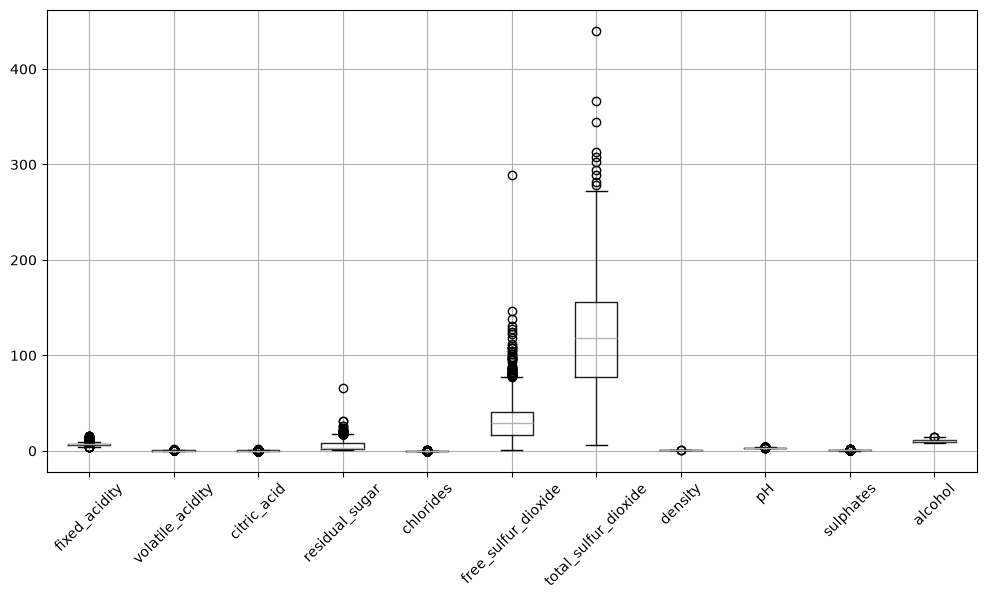

In [25]:
#Outlier finder

import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
X.boxplot(rot=45)
plt.show()

In [8]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = ((X < (Q1 - 1.5 * IQR)) |
            (X > (Q3 + 1.5 * IQR)))

print(outliers.sum())


fixed_acidity           357
volatile_acidity        377
citric_acid             509
residual_sugar          118
chlorides               286
free_sulfur_dioxide      62
total_sulfur_dioxide     10
density                   3
pH                       73
sulphates               191
alcohol                   3
dtype: int64


In [26]:
X.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


In [10]:
import pandas as pd

# Combine features and target
df = pd.concat([X, y], axis=1)

# Create cleaned dataset
data_clean = df.drop_duplicates()

# Verify
print("Original shape:", df.shape)
print("Cleaned shape:", data_clean.shape)

Original shape: (6497, 12)
Cleaned shape: (5318, 12)


In [11]:
#There were lots of nulls and duplicates in the dataset so I had to fix them by removing them.

In [12]:
data_clean = (
    pd.concat([X, y], axis=1)
      .drop_duplicates()
      .dropna()
)

In [13]:
print(data_clean.info())
print("\nMissing Values:")
print(data_clean.isnull().sum())

<class 'pandas.DataFrame'>
Index: 5318 entries, 0 to 6496
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         5318 non-null   float64
 1   volatile_acidity      5318 non-null   float64
 2   citric_acid           5318 non-null   float64
 3   residual_sugar        5318 non-null   float64
 4   chlorides             5318 non-null   float64
 5   free_sulfur_dioxide   5318 non-null   float64
 6   total_sulfur_dioxide  5318 non-null   float64
 7   density               5318 non-null   float64
 8   pH                    5318 non-null   float64
 9   sulphates             5318 non-null   float64
 10  alcohol               5318 non-null   float64
 11  quality               5318 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 540.1 KB
None

Missing Values:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides       

Text(0.5, 1.0, 'Distribution of Alcohol Percentage Across Wines')

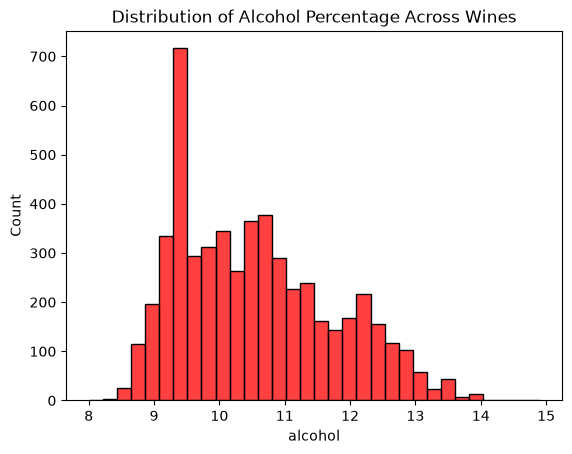

In [34]:
sns.histplot(data=data_clean, x='alcohol', color="Red")
plt.title("Distribution of Alcohol Percentage Across Wines")

Text(0.5, 1.0, 'Comparison of Alcohol Levels Across Wine Quality Scores')

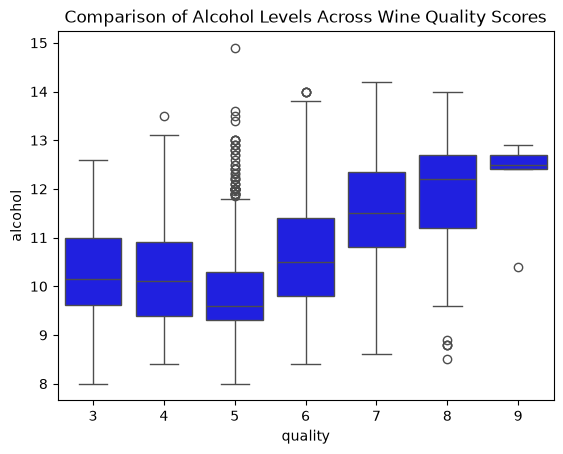

In [38]:
sns.boxplot(data=data_clean, x='quality', y='alcohol', color="Blue")
plt.title("Comparison of Alcohol Levels Across Wine Quality Scores")

Text(0.5, 1.0, 'Correlation Between Alcohol Content and Density')

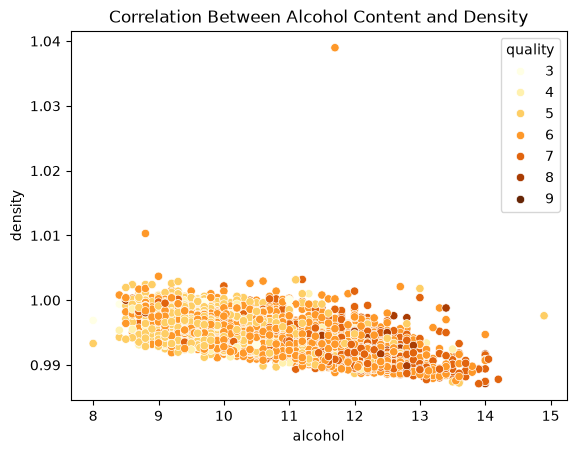

In [63]:
sns.scatterplot(
    data=data_clean,
    x='alcohol',
    y='density',
    hue='quality',
    palette='YlOrBr'
)
plt.title("Correlation Between Alcohol Content and Density")

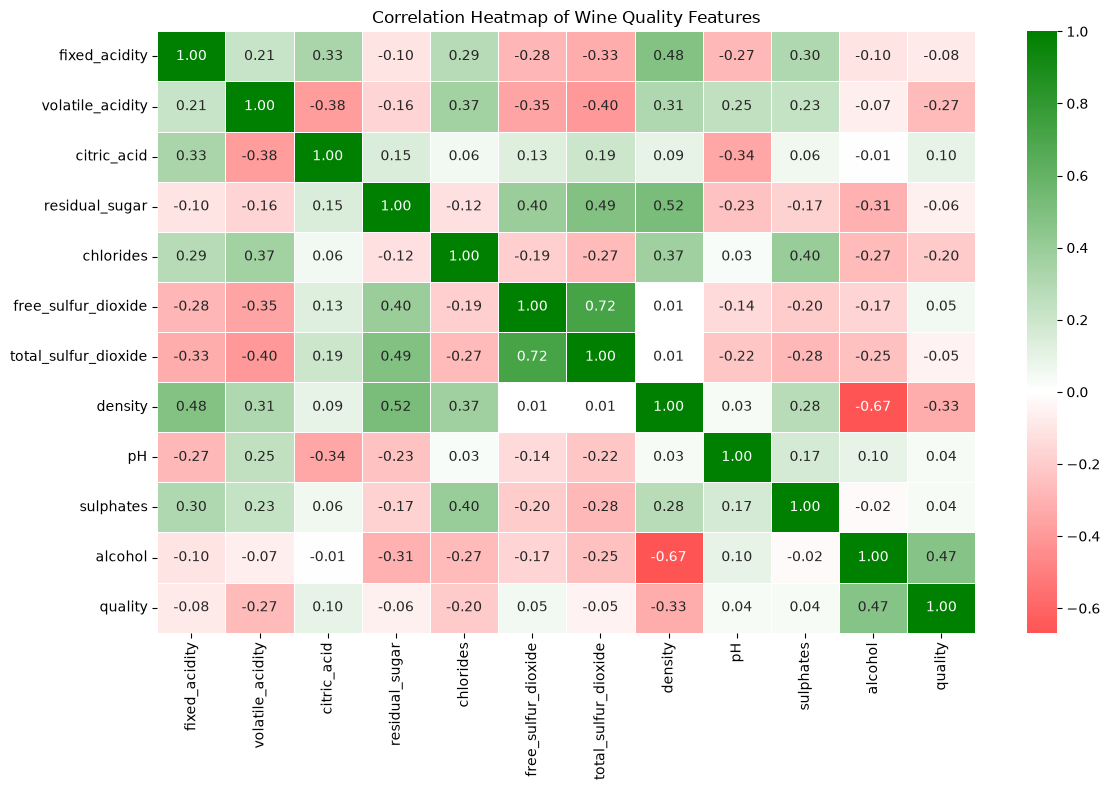

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Custom color map: Red -> White -> Green
cmap = LinearSegmentedColormap.from_list(
    "RedWhiteGreen",
    ["red", "white", "green"]
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    data_clean.corr(numeric_only=True),
    annot=True,
    cmap=cmap,
    center=0,      # Makes white represent 0 correlation
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Quality Features")
plt.tight_layout()
plt.show()


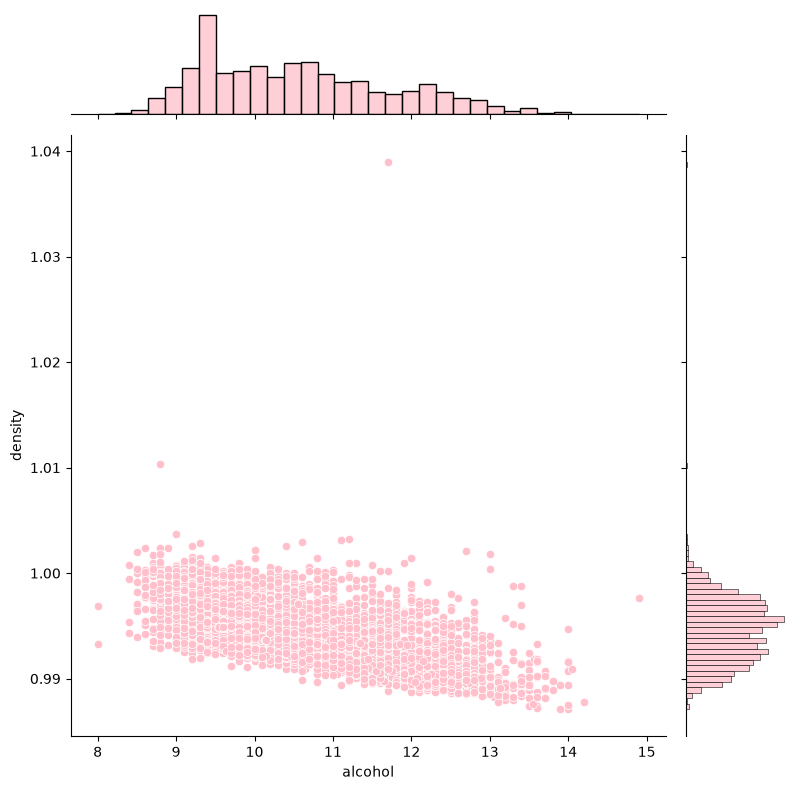

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

# Joint Plot with KDE marginals
g = sns.jointplot(
    data=data_clean,
    x='alcohol',
    y='density',
    kind='scatter',
    height=8,
    color='Pink',
    marginal_kws={
        'fill': True,
        'color': 'Pink'
    }
)

g.ax_joint.set_title(
    'Relationship Between Alcohol Content and Wine Density',
    pad=20
)

plt.show()

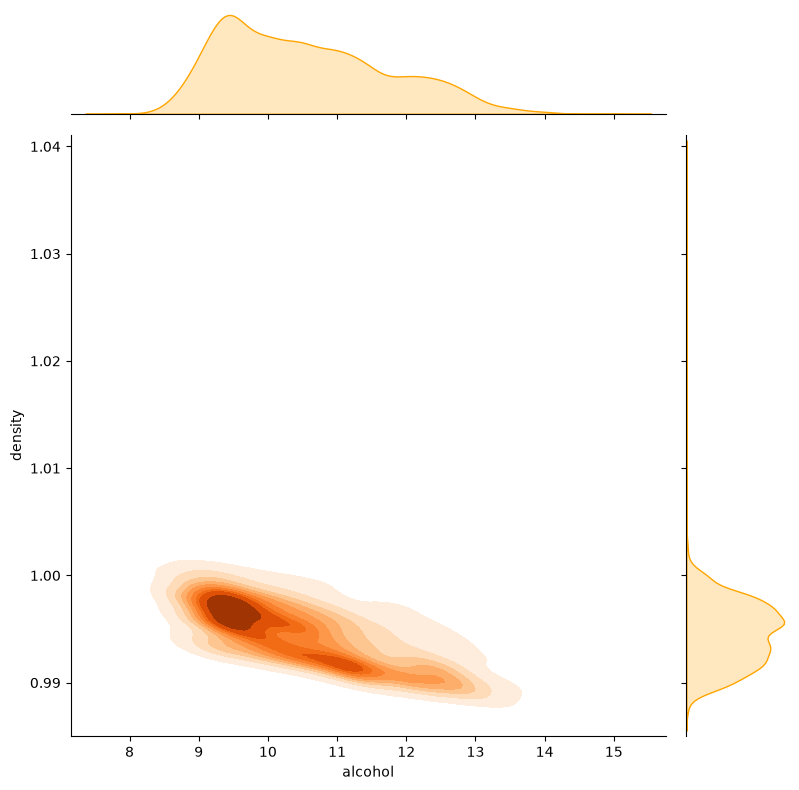

In [58]:
g = sns.jointplot(
    data=data_clean,
    x='alcohol',
    y='density',
    kind='kde',
    fill=True,
    cmap='Oranges',
    height=8,
    marginal_kws={
            'fill': True,
            'color': 'Orange'
    }
)

g.ax_joint.set_title(
    'Relationship Between Alcohol Content and Wine Density',
    pad=20
)

plt.show()


In [20]:
data_clean.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000,5318.000000
mean,7.215523,0.344171,0.318522,5.049605,0.056700,30.030463,114.107747,0.994536,3.224639,0.533402,10.549222,5.795600
std,1.319777,0.168264,0.147177,4.500645,0.036865,17.804365,56.783848,0.002966,0.160403,0.149753,1.185964,0.879715
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,16.000000,74.000000,0.992200,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,2.700000,0.047000,28.000000,116.000000,0.994660,3.210000,0.510000,10.400000,6.000000
75%,7.700000,0.410000,0.400000,7.500000,0.066000,41.000000,153.750000,0.996770,3.330000,0.600000,11.400000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [21]:
# High alcohol
data_clean[data_clean['alcohol'] > 12][['alcohol']].head()


,alcohol
45,13.1
95,12.9
131,13.0
142,14.0
198,13.0


In [22]:
# High quality
data_clean[data_clean['quality'] >= 7][['quality']].head()

,quality
7,7
8,7
16,7
37,7
62,7


In [23]:
# High quality and high alcohol
data_clean[
    (data_clean['quality'] >= 7) &
    (data_clean['alcohol'] > 12)
][['quality', 'alcohol']].head()

,quality,alcohol
198,7,13.0
230,7,12.2
267,8,12.8
278,8,12.6
335,7,12.2
